# Fase 3 — Fine-tuning multi-gerador (a partir do `phase2_final.pt`)

**Por que existe:** a Fase 2 só viu rostos de StyleGAN, então imagens de Gemini/ChatGPT caíam em "real". Aqui o treino usa o dataset **OpenFake** (Hugging Face, via *streaming*) com geradores recentes (GPT-image, Imagen, Nano Banana, Flux, SD, Midjourney...), reais de várias fontes (rostos **e cenas**) e avaliação **por gerador**, com geradores inteiros fora do treino.

**Espaço:** os dados ficam no disco **local** do Colab (`/content`) e somem ao encerrar a sessão. No Drive vão só checkpoints (`best.pt` ~45 MB, `last.pt` ~130 MB com otimizador, `phase3_final.pt` ~45 MB; apague o `last.pt` quando terminar).

**Fluxo:** configuração → Drive → download amostrado (streaming) → checagem de atalhos → loaders → modelo da Fase 2 → **baseline da Fase 2 no novo teste** → treino → calibração e teste por gerador → suas imagens.

**Limites declarados**
- A lógica de amostragem foi testada com dados simulados, mas o acesso real ao Hugging Face **não** foi testado. Se a célula de download falhar, envie o traceback.
- OpenFake é CC-BY-NC-4.0: serve para TCC, não para uso comercial.
- Ele não lista o Gemini original, mas as versões atuais trazem `nano-banana-pro`, `imagen-4.0` e `gpt-image-*`. Confira na célula de download quais nomes apareceram de fato.
- Os reais do OpenFake vêm de LAION/Pexels/DOCCI/ImageNet; fotos de celular, WhatsApp e redes sociais não estão bem representadas.

In [1]:
!pip install -q datasets scikit-learn
!pip -q install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 41.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


### Configuração (ajuste só aqui)

In [2]:
import os, io, csv, json, math, time, random, collections
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image, ImageFilter
from sklearn.metrics import confusion_matrix, roc_auc_score

os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_ETAG_TIMEOUT"] = "30"

CFG = dict(
    RUN_NAME="fase3_multigerador",        # pasta do experimento (dentro de .../modelos/)
    PHASE2_CKPT="/content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn/phase2_final.pt",

    # --- dados (OpenFake, em streaming) ---
    HF_REPO="ComplexDataLab/OpenFake", HF_CONFIG="core",
    DATA_DIR="/content/data/p3",          # disco LOCAL do Colab: não ocupa o Drive, some ao fim da sessão
    SHORT_SIDE=512,                       # lado curto máximo salvo (reduz disco e iguala resolução de reais e fakes)
    JPEG_QUALITY=92,                      # TODAS as imagens salvas em JPEG com a mesma qualidade (reduz atalho de formato)
    MIN_SIDE=256,                         # descarta imagens menores que isso
    CAP_FAKE_TRAIN=100, CAP_FAKE_TEST=40, # imagens fake por gerador (treino / teste)
    PRIORITY_MULT=3,                      # geradores-alvo ganham cota multiplicada por isso
    PRIORITY_KEYS=("gpt-image", "nano-banana", "imagen", "dall"),
    CAP_REAL_TRAIN=1500, CAP_REAL_TEST=500,   # imagens reais por FONTE (laion, pexels, docci, imagenet...)
    MAX_SCAN_TRAIN=30000, MAX_SCAN_TEST=15000, MAX_MINUTES=30,   # limites de varredura do stream, por split
    HOLDOUT=("flux.2-dev", "sd-3.5"),     # geradores FORA do treino: medem generalização para gerador não visto
    REPLAY_DIR="/content/data/faces", REPLAY_PER_CLASS=1500,     # opcional: reaproveita faces da Fase 2 se a pasta existir

    # --- treino ---
    SEED=42, CROP=224, BATCH_SIZE=64, NUM_WORKERS=min(4, os.cpu_count() or 2),
    EPOCHS=8, WARMUP=1, PATIENCE=3,
    LR_VIT=2e-5, LR_FFT=5e-5, LR_CNN=5e-5, LR_HEAD=1e-4,   # menores que na Fase 2: é ajuste fino, não treino do zero
    WEIGHT_DECAY=1e-4, LABEL_SMOOTHING=0.1, MAX_GRAD_NORM=1.0,
    VAL_FRAC=0.10,                        # fração do pool de treino para CADA validação (early stopping e calibração)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Ative a GPU: Ambiente de execução > Alterar o tipo de ambiente de execução."
print("GPU:", torch.cuda.get_device_name(0))


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


set_seed(CFG["SEED"])
torch.backends.cudnn.benchmark = True

GPU: Tesla T4


Teste Token Hugging Face

In [3]:

from google.colab import userdata

hf_token = userdata.get("HF_TOKEN")

if hf_token and hf_token.startswith("hf_"):
    print("Token encontrado e carregado.")
else:
    print("Token ausente ou com formato inesperado.")


Token encontrado e carregado.


### Drive, pastas e checkpoint da Fase 2

In [4]:
import shutil
from google.colab import drive
drive.mount("/content/drive")

assert os.path.isfile(CFG["PHASE2_CKPT"]), f"Não achei {CFG['PHASE2_CKPT']}: ajuste CFG['PHASE2_CKPT'] na célula de configuração."
DRIVE_ROOT = os.path.dirname(os.path.dirname(CFG["PHASE2_CKPT"]))      # .../modelos
RUN_DIR = os.path.join(DRIVE_ROOT, CFG["RUN_NAME"])
os.makedirs(RUN_DIR, exist_ok=True)
os.makedirs(CFG["DATA_DIR"], exist_ok=True)
LAST_CKPT = os.path.join(RUN_DIR, "last.pt")        # estado completo (retomada)
BEST_CKPT = os.path.join(RUN_DIR, "best.pt")        # só os melhores pesos
HISTORY_CSV = os.path.join(RUN_DIR, "history.csv")


def free_gb(path):
    # espaço livre em GB (devolve nan se o caminho não permitir consulta)
    try:
        return shutil.disk_usage(path).free / 1e9
    except Exception:
        return float("nan")


print("Pasta do experimento:", RUN_DIR)
print(f"Livre no disco local do Colab: {free_gb('/content'):.1f} GB | no Drive: {free_gb('/content/drive'):.1f} GB")
print("Estimativa de disco local para os dados: ~2 a 4 GB (com as cotas padrão).")

Mounted at /content/drive
Pasta do experimento: /content/drive/MyDrive/TCC_Final/modelos/fase3_multigerador
Livre no disco local do Colab: 207.5 GB | no Drive: 10.8 GB
Estimativa de disco local para os dados: ~2 a 4 GB (com as cotas padrão).


### Funções de coleta (amostragem por gerador a partir do stream)

In [5]:
def safe_name(s):
    # troca caracteres estranhos (barra, espaço) por '-': o nome do gerador vira parte do nome do arquivo
    return "".join(ch if (ch.isalnum() or ch in "-.") else "-" for ch in str(s))


def is_priority(name):
    # geradores-alvo (ChatGPT / Gemini / Imagen / DALL-E) ganham cota maior
    return any(k in str(name).lower() for k in CFG["PRIORITY_KEYS"])


def label_to_str(lab, label_names):
    # aceita o rótulo como texto ("real"/"fake") ou como inteiro, desde que haja os nomes das classes
    if isinstance(lab, (int, np.integer)):
        if not label_names:
            raise ValueError("Rótulo inteiro sem nomes de classe: não sei qual é real e qual é fake.")
        lab = label_names[int(lab)]
    return str(lab).strip().lower()


def collect_split(rows, split, cap_fake, cap_real, max_scan, label_names=None, exclude=()):
    # rows: iterável de dicts {"image": {"bytes": ...}, "label": ..., "model": ...}
    # Salva até `cap_*` imagens por grupo (fake: por gerador | real: por fonte) em DATA_DIR/<split>/<classe>/
    # e devolve o manifesto (lista de dicts com caminho, rótulo, grupo e dados do arquivo original).
    out_root = os.path.join(CFG["DATA_DIR"], split)
    for cls in ("real", "fake"):
        os.makedirs(os.path.join(out_root, cls), exist_ok=True)
    counts, manifest = {}, []
    t0, scanned = time.time(), 0
    for row in rows:
        scanned += 1
        if scanned > max_scan or (time.time() - t0) / 60 > CFG["MAX_MINUTES"]:
            break                                                    # limite de varredura ou de tempo
        lab = label_to_str(row["label"], label_names)                # levanta ValueError se o rótulo for inteiro sem nomes de classe
        name = str(row["model"])                                   # gerador (fake) ou fonte (real)
        if lab not in ("real", "fake"):
            continue
        if lab == "fake" and name in exclude:
            continue                                                 # hold-out: não entra neste split
        cap = cap_real if lab == "real" else cap_fake * (CFG["PRIORITY_MULT"] if is_priority(name) else 1)
        key = (lab, name)
        if counts.get(key, 0) >= cap:
            continue                                                 # cota deste grupo já preenchida
        try:
            raw = row["image"]
            im = Image.open(io.BytesIO(raw["bytes"])) if isinstance(raw, dict) else raw
            fmt, (w0, h0) = im.format, im.size                       # formato e tamanho ORIGINAIS (para a checagem de atalhos)
            im = im.convert("RGB")
        except Exception:
            continue                                                 # arquivo corrompido: ignora
        if min(im.size) < CFG["MIN_SIDE"]:
            continue
        s = min(im.size)
        if s > CFG["SHORT_SIDE"]:                                    # reduz só quando maior; nunca amplia
            k = CFG["SHORT_SIDE"] / s
            im = im.resize((round(im.width * k), round(im.height * k)), Image.LANCZOS)
        idx = counts.get(key, 0)
        path = os.path.join(out_root, lab, f"{safe_name(name)}__{idx:05d}.jpg")
        im.save(path, format="JPEG", quality=CFG["JPEG_QUALITY"])
        counts[key] = idx + 1
        manifest.append({"path": path, "label": 0 if lab == "real" else 1, "group": name,
                         "orig_format": fmt, "orig_w": w0, "orig_h": h0})
        if scanned % 2000 == 0:
            print(f"  [{split}] varridas={scanned} | salvas={len(manifest)} | {(time.time() - t0) / 60:.1f} min")
    n_real = sum(1 for m in manifest if m["label"] == 0)
    print(f"[{split}] varridas={scanned} | salvas={len(manifest)} (reais={n_real}, fakes={len(manifest) - n_real}) "
          f"| grupos fake={len({m['group'] for m in manifest if m['label'] == 1})} "
          f"| reais por fonte={len({m['group'] for m in manifest if m['label'] == 0})} | {(time.time() - t0) / 60:.1f} min")
    return manifest

### Download amostrado do OpenFake (streaming: nada é baixado por inteiro)

In [6]:
manifest_path = os.path.join(CFG["DATA_DIR"], "manifest.json")

if os.path.isfile(manifest_path):
    MANIFEST = json.load(open(manifest_path))
    print("Manifesto existente reaproveitado:", manifest_path)
else:
    from datasets import load_dataset, Image as HFImage
    try:
        from google.colab import userdata
        hf_token = userdata.get("HF_TOKEN")        # opcional (Secrets do Colab); sem token o acesso anônimo também funciona
    except Exception:
        hf_token = None

    def open_stream(hf_split):
        # abre o split em streaming, sem decodificar imagens (só bytes) e com embaralhamento por shard + buffer pequeno
        ds = load_dataset(CFG["HF_REPO"], CFG["HF_CONFIG"], split=hf_split, streaming=True, token=hf_token)
        ds = ds.cast_column("image", HFImage(decode=False))
        feats = ds.features or {}
        names = getattr(feats.get("label"), "names", None)       # nomes de classe, se o rótulo for inteiro
        return ds.shuffle(seed=CFG["SEED"], buffer_size=300), names   # buffer pequeno: cada linha tem ~1 MB

    MANIFEST = {}
    for hf_split in ("train", "validation"):       # pool de treino: usa "train"; se o split não abrir, cai para "validation"
        try:
            ds, names = open_stream(hf_split)
            MANIFEST["train"] = collect_split(ds, "train", CFG["CAP_FAKE_TRAIN"], CFG["CAP_REAL_TRAIN"],
                                              CFG["MAX_SCAN_TRAIN"], names, exclude=CFG["HOLDOUT"])
            break
        except Exception as e:
            print(f"Falha ao ler o split '{hf_split}': {type(e).__name__}: {e}")
    assert "train" in MANIFEST, "Não consegui ler nenhum split de treino do OpenFake (veja o erro acima)."

    ds, names = open_stream("test")                # teste: split separado, com TODOS os geradores (inclusive hold-out)
    MANIFEST["test"] = collect_split(ds, "test", CFG["CAP_FAKE_TEST"], CFG["CAP_REAL_TEST"],
                                     CFG["MAX_SCAN_TEST"], names, exclude=())
    json.dump(MANIFEST, open(manifest_path, "w"))

seen_test = {r["group"] for r in MANIFEST["test"] if r["label"] == 1}
for g in CFG["HOLDOUT"]:
    if g not in seen_test:
        print(f"ATENÇÃO: hold-out '{g}' não apareceu no teste; confira o nome exato (coluna 'model') ou aumente MAX_SCAN_TEST.")
print("Geradores fake no teste:", sorted(seen_test))
print("Fontes reais no teste:", sorted({r["group"] for r in MANIFEST["test"] if r["label"] == 0}))
alvo = sorted(g for g in seen_test if is_priority(g))
print("Geradores-alvo presentes (ChatGPT/Gemini/Imagen/DALL-E):", alvo or "NENHUM: o dataset pode ter mudado de nomes")

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

  [train] varridas=2000 | salvas=1744 | 4.4 min


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  [train] varridas=4000 | salvas=3306 | 8.6 min
[train] varridas=14146 | salvas=6425 (reais=3000, fakes=3425) | grupos fake=71 | reais por fonte=2 | 30.0 min


Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

[test] varridas=15001 | salvas=1947 (reais=1000, fakes=947) | grupos fake=20 | reais por fonte=2 | 10.7 min
ATENÇÃO: hold-out 'flux.2-dev' não apareceu no teste; confira o nome exato (coluna 'model') ou aumente MAX_SCAN_TEST.
ATENÇÃO: hold-out 'sd-3.5' não apareceu no teste; confira o nome exato (coluna 'model') ou aumente MAX_SCAN_TEST.
Geradores fake no teste: ['aurora-20-1-25', 'ernie-image', 'ernie-image-turbo', 'flux.2-klein-9b', 'frames-23-1-25', 'gpt-image-1.5', 'gpt-image-2', 'halfmoon-4-4-25', 'ideogram-2.0', 'illustrious', 'lumina-17-2-25', 'midjourney-7', 'nano-banana-pro', 'recraft-v2', 'recraft-v3', 'seedream-v5.0', 'sora-2', 'veo-3', 'wan-video-2.5', 'z-image-turbo']
Fontes reais no teste: ['docci', 'imagenet']
Geradores-alvo presentes (ChatGPT/Gemini/Imagen/DALL-E): ['gpt-image-1.5', 'gpt-image-2', 'nano-banana-pro']


### Checagem de atalhos: reais e fakes diferem em formato ou resolução original?

In [7]:
# Se reais e fakes diferem muito em formato/resolução ORIGINAL, o modelo pode aprender isso em vez de aprender "IA".
# Os arquivos salvos já são todos JPEG com mesma qualidade e lado curto <= 512, mas sinais residuais (dupla compressão,
# tamanho de origem) podem sobrar. Esta tabela serve para você enxergar o risco, não para eliminá-lo.
for split in ("train", "test"):
    jpeg_share = {}
    for lab, nm in ((0, "real"), (1, "fake")):
        sub = [r for r in MANIFEST[split] if r["label"] == lab]
        if not sub:
            continue
        fmts = collections.Counter(r["orig_format"] for r in sub)
        ss = np.array([min(r["orig_w"], r["orig_h"]) for r in sub])
        jpeg_share[nm] = fmts.get("JPEG", 0) / len(sub)
        print(f"{split:5s} {nm:4s} n={len(sub):5d} | formatos originais: {dict(fmts.most_common(4))} | "
              f"lado curto original p10/p50/p90 = {np.percentile(ss, [10, 50, 90]).astype(int).tolist()}")
    if len(jpeg_share) == 2 and abs(jpeg_share["real"] - jpeg_share["fake"]) > 0.5:
        print(f"  >>> ATENÇÃO ({split}): a fração de JPEG original difere muito entre reais e fakes "
              f"({jpeg_share['real']:.0%} x {jpeg_share['fake']:.0%}). Risco de atalho de formato/compressão.")

train real n= 3000 | formatos originais: {'JPEG': 2965, 'PNG': 22, 'WEBP': 13} | lado curto original p10/p50/p90 = [420, 1907, 4160]
train fake n= 3425 | formatos originais: {'PNG': 1782, 'JPEG': 1539, 'WEBP': 104} | lado curto original p10/p50/p90 = [512, 832, 1024]
  >>> ATENÇÃO (train): a fração de JPEG original difere muito entre reais e fakes (99% x 45%). Risco de atalho de formato/compressão.
test  real n= 1000 | formatos originais: {'JPEG': 1000} | lado curto original p10/p50/p90 = [333, 588, 1536]
test  fake n=  947 | formatos originais: {'JPEG': 507, 'PNG': 424, 'WEBP': 16} | lado curto original p10/p50/p90 = [720, 1024, 1440]


### Transforms (em sessão nova, rodar esta célula antes de testar imagens próprias)

In [8]:
NORM_MEAN, NORM_STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)    # normalização para [-1, 1], igual à Fase 2
CROP = CFG["CROP"]


class RandomJPEG:
    # Augmentation: recomprime em JPEG com qualidade aleatória (simula imagens que circularam na internet)
    def __init__(self, p=0.3, quality=(60, 95)):
        self.p, self.quality = p, quality

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=random.randint(*self.quality))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


class RandomBlur:
    # Augmentation: desfoque gaussiano leve, com probabilidade p
    def __init__(self, p=0.1, radius=(0.3, 1.2)):
        self.p, self.radius = p, radius

    def __call__(self, img):
        if random.random() > self.p:
            return img
        return img.filter(ImageFilter.GaussianBlur(random.uniform(*self.radius)))


class RandomDownUp:
    # Augmentation: reduz e amplia de volta (simula redimensionamentos feitos por apps e redes sociais)
    def __init__(self, p=0.15, scale=(0.5, 0.9)):
        self.p, self.scale = p, scale

    def __call__(self, img):
        if random.random() > self.p:
            return img
        k = random.uniform(*self.scale)
        w, h = img.size
        small = img.resize((max(8, int(w * k)), max(8, int(h * k))), Image.BILINEAR)
        return small.resize((w, h), Image.BICUBIC)


_to_norm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)])

# Treino: recorte aleatório 224 de uma imagem de lado curto <= 512 (preserva a textura local, sem Resize destrutivo)
train_tf = transforms.Compose([transforms.RandomCrop(CROP, pad_if_needed=True), transforms.RandomHorizontalFlip(),
                               RandomBlur(0.1), RandomDownUp(0.15), RandomJPEG(0.3, (60, 95)), _to_norm])
# Validação rápida (early stopping): recorte central
eval_tf = transforms.Compose([transforms.CenterCrop(CROP), _to_norm])
# Calibração, teste e uso real: 5 recortes (4 cantos + centro); os logits são promediados
_five = transforms.FiveCrop(CROP)


def multicrop_tf(img):
    return torch.stack([_to_norm(c) for c in _five(img)])    # (5, 3, 224, 224)


# Só para o baseline da Fase 2: o pré-processamento ORIGINAL dela (Resize da imagem inteira para 224x224)
phase2_tf = transforms.Compose([transforms.Resize((CROP, CROP)), _to_norm])

### Splits (estratificados por gerador), amostragem balanceada e loaders

In [9]:
def find_faces_root(base):
    # localiza a pasta com train/real e train/fake dentro de `base` (estrutura do dataset de faces da Fase 2)
    for dirpath, _, _ in os.walk(base):
        if all(os.path.isdir(os.path.join(dirpath, "train", c)) for c in ("real", "fake")):
            return dirpath
    return None


def replay_rows(n_per_class):
    # Opcional: amostra faces da Fase 2 para o modelo não esquecer StyleGAN. Vazio se a pasta não existir.
    base = CFG["REPLAY_DIR"]
    if not base or not os.path.isdir(base):
        return []
    root = find_faces_root(base)
    if root is None:
        return []
    rng, rows = random.Random(CFG["SEED"]), []
    for lab, cls in ((0, "real"), (1, "fake")):
        d = os.path.join(root, "train", cls)
        files = sorted(os.listdir(d))
        rng.shuffle(files)
        rows += [{"path": os.path.join(d, f), "label": lab, "group": f"faces-{cls}"} for f in files[:n_per_class]]
    return rows


def split_by_group(rows, frac, seed):
    # Divide em treino / validação A / validação B mantendo a proporção de CADA grupo (gerador ou fonte).
    # Grupos com menos de 10 imagens vão inteiros para o treino.
    rng = random.Random(seed)
    by_g = collections.defaultdict(list)
    for r in rows:
        by_g[(r["label"], r["group"])].append(r)
    tr, v1, v2 = [], [], []
    for _, lst in sorted(by_g.items()):
        rng.shuffle(lst)
        k = int(len(lst) * frac) if len(lst) >= 10 else 0
        v1 += lst[:k]; v2 += lst[k:2 * k]; tr += lst[2 * k:]
    return tr, v1, v2


def sampler_weights(rows):
    # Peso de cada imagem = 1 / (nº de grupos da classe x tamanho do seu grupo):
    # classes ficam 50/50 e cada gerador/fonte contribui igual, mesmo que tenha menos imagens.
    cnt = collections.Counter((r["label"], r["group"]) for r in rows)
    ngr = collections.Counter(lab for (lab, _) in cnt)
    return [1.0 / (ngr[r["label"]] * cnt[(r["label"], r["group"])]) for r in rows]


class PathDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows, self.transform = rows, transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows[i]
        return self.transform(Image.open(r["path"]).convert("RGB")), r["label"]


train_pool = MANIFEST["train"] + replay_rows(CFG["REPLAY_PER_CLASS"])
tr_rows, ves_rows, vcal_rows = split_by_group(train_pool, CFG["VAL_FRAC"], CFG["SEED"])
test_rows = MANIFEST["test"]

# Garantias: nenhuma imagem em dois conjuntos e nenhum gerador hold-out no treino
paths = [set(r["path"] for r in s) for s in (tr_rows, ves_rows, vcal_rows, test_rows)]
assert all(not (paths[i] & paths[j]) for i in range(4) for j in range(i + 1, 4)), "Há imagens repetidas entre conjuntos."
assert not any(r["group"] in CFG["HOLDOUT"] and r["label"] == 1 for r in train_pool), "Gerador hold-out vazou para o treino."

nw = CFG["NUM_WORKERS"]
train_loader = DataLoader(PathDataset(tr_rows, train_tf), batch_size=CFG["BATCH_SIZE"],
                          sampler=WeightedRandomSampler(sampler_weights(tr_rows), num_samples=len(tr_rows), replacement=True),
                          num_workers=nw, pin_memory=True, drop_last=True, persistent_workers=nw > 0)
ves_loader = DataLoader(PathDataset(ves_rows, eval_tf), batch_size=128, shuffle=False, num_workers=nw, pin_memory=True)
vcal_loader = DataLoader(PathDataset(vcal_rows, multicrop_tf), batch_size=16, shuffle=False, num_workers=nw, pin_memory=True)
test_loader = DataLoader(PathDataset(test_rows, multicrop_tf), batch_size=16, shuffle=False, num_workers=nw, pin_memory=True)
base_loader = DataLoader(PathDataset(test_rows, phase2_tf), batch_size=64, shuffle=False, num_workers=nw, pin_memory=True)

print(f"Treino: {len(tr_rows)} | validação (early stopping): {len(ves_rows)} | validação (calibração): {len(vcal_rows)} | teste: {len(test_rows)}")
print(f"Teste: reais={sum(r['label'] == 0 for r in test_rows)} | fakes={sum(r['label'] == 1 for r in test_rows)} "
      f"| fakes de gerador hold-out (não visto)={sum(r['label'] == 1 and r['group'] in CFG['HOLDOUT'] for r in test_rows)}")

Treino: 5187 | validação (early stopping): 619 | validação (calibração): 619 | teste: 1947
Teste: reais=1000 | fakes=947 | fakes de gerador hold-out (não visto)=0


### Modelo: arquitetura da Fase 2 + pesos do `phase2_final.pt`

In [10]:
# Arquitetura IDÊNTICA à da Fase 2 (nomes de módulos precisam casar com o checkpoint).
# ---------- Componentes da Fase 1 (NÃO alterar: precisam casar com os pesos salvos) ----------
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=192):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        attn = self.dropout(attn)
        return self.proj((attn @ v).transpose(1, 2).reshape(B, N, C))


class MLPBlock(nn.Module):
    def __init__(self, embed_dim, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        hidden = int(embed_dim * mlp_ratio)
        self.fc1 = nn.Linear(embed_dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.dropout(self.act(self.fc1(x)))
        return self.dropout(self.fc2(x))


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLPBlock(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class ViTTiny(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3,
                 embed_dim=192, depth=12, num_heads=3, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        n = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, embed_dim))
        self.pos_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
                                     for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = torch.cat([self.cls_token.expand(B, -1, -1), self.patch_embed(x)], dim=1)
        x = self.pos_dropout(x + self.pos_embed)
        for blk in self.blocks:
            x = blk(x)
        return self.norm(x)[:, 0]


class FFTBranch(nn.Module):
    def __init__(self, in_channels=3, out_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, out_dim)

    @staticmethod
    def to_log_magnitude_spectrum(x):
        fft = torch.fft.fftshift(torch.fft.fft2(x, norm="ortho"), dim=(-2, -1))
        return torch.log1p(torch.abs(fft))

    def forward(self, x):
        feat = self.conv(self.to_log_magnitude_spectrum(x))
        return self.fc(self.pool(feat).flatten(1))


# ---------- Novo na Fase 2 ----------
class CNNBranch(nn.Module):
    # EfficientNet-B0 (ImageNet) -> vetor de 1280 dims. Converte a normalização [-1,1] do projeto
    # para a normalização esperada pelos pesos do ImageNet.
    def __init__(self, pretrained=True):
        super().__init__()
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x * 0.5 + 0.5 - self.mean) / self.std
        return self.pool(self.features(x)).flatten(1)


class Phase2Detector(nn.Module):
    DIMS = {"vit": 192, "fft": 128, "cnn": 1280}

    def __init__(self, branches=("vit", "fft", "cnn"), fusion="gate", proj_dim=256,
                 pretrained_cnn=True, num_classes=2, dropout=0.2):
        super().__init__()
        self.names = [n for n in ("vit", "fft", "cnn") if n in branches]
        self.fusion = fusion
        mods = {}
        if "vit" in self.names: mods["vit"] = ViTTiny(embed_dim=192)
        if "fft" in self.names: mods["fft"] = FFTBranch(out_dim=128)
        if "cnn" in self.names: mods["cnn"] = CNNBranch(pretrained_cnn)
        self.branches = nn.ModuleDict(mods)
        self.proj = nn.ModuleDict({n: nn.Sequential(nn.LayerNorm(self.DIMS[n]), nn.Linear(self.DIMS[n], proj_dim))
                                   for n in self.names})
        k = len(self.names)
        if fusion == "gate":
            self.gate = nn.Sequential(nn.Linear(k * proj_dim, 64), nn.GELU(), nn.Linear(64, k))
            cls_in = proj_dim
        else:
            self.gate = None
            cls_in = k * proj_dim
        self.classifier = nn.Sequential(nn.LayerNorm(cls_in), nn.Linear(cls_in, 128), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x, return_gate=False):
        feats = [self.proj[n](self.branches[n](x)) for n in self.names]
        gate_w = None
        if self.fusion == "gate":
            gate_w = torch.softmax(self.gate(torch.cat(feats, dim=1)), dim=1)          # (B, k)
            fused = (torch.stack(feats, dim=1) * gate_w.unsqueeze(-1)).sum(dim=1)       # (B, D)
        else:
            fused = torch.cat(feats, dim=1)
        logits = self.classifier(fused)
        return (logits, gate_w) if return_gate else logits


# ---------- carrega o checkpoint final da Fase 2 ----------
# weights_only=False porque o arquivo guarda também dicionários (cfg, T, limiar); só abra arquivos seus.
ck2 = torch.load(CFG["PHASE2_CKPT"], map_location="cpu", weights_only=False)
cfg2 = ck2["cfg"]                                           # configuração de arquitetura usada na Fase 2
model = Phase2Detector(branches=cfg2["BRANCHES"], fusion=cfg2["FUSION"], proj_dim=cfg2["PROJ_DIM"],
                       pretrained_cnn=False)                # os pesos vêm do checkpoint
model.load_state_dict(ck2["model_state_dict"])
model = model.to(device)
T2, THR2 = float(ck2["temperature"]), float(ck2["threshold"])   # calibração e limiar da Fase 2 (usados só no baseline)
print(f"Fase 2 carregada | ramos: {model.names} | fusão: {cfg2['FUSION']} | T2={T2:.3f} | limiar2={THR2:.3f} "
      f"| parâmetros: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

Fase 2 carregada | ramos: ['vit', 'fft', 'cnn'] | fusão: gate | T2=0.391 | limiar2=0.725 | parâmetros: 10.06M


### Métricas e utilitários

In [11]:
def binary_metrics(y_true, y_pred):
    # métricas com fake = classe positiva
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec, rec = tp / max(1, tp + fp), tp / max(1, tp + fn)
    tnr = tn / max(1, tn + fp)
    return {"accuracy": (tp + tn) / len(y_true), "precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(1e-12, prec + rec), "tnr": tnr, "bal_acc": (rec + tnr) / 2,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


@torch.no_grad()
def collect_center(model, loader):
    # logits com 1 recorte por imagem (loaders de recorte central ou Resize)
    model.eval()
    L, Y = [], []
    for imgs, labels in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            lg = model(imgs.to(device, non_blocking=True))
        L.append(lg.float().cpu()); Y.append(labels)
    return torch.cat(L), torch.cat(Y)


@torch.no_grad()
def collect_tta(model, loader):
    # logits médios sobre 5 recortes por imagem (loaders com multicrop_tf)
    model.eval()
    L, Y = [], []
    for imgs, labels in loader:                                    # imgs: (B, 5, 3, H, W)
        B = imgs.size(0)
        x = imgs.to(device, non_blocking=True).flatten(0, 1)       # (B*5, 3, H, W)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            lg = model(x)
        L.append(lg.float().view(B, 5, -1).mean(1).cpu()); Y.append(labels)
    return torch.cat(L), torch.cat(Y)


def evaluate_center(model, loader):
    # validação rápida durante o treino: loss, AUC (independe de limiar) e acurácia balanceada @0.5
    lg, y = collect_center(model, loader)
    p = F.softmax(lg, 1)[:, 1].numpy()
    yn = y.numpy()
    m = binary_metrics(yn, (p >= 0.5).astype(int))
    return {"loss": float(F.cross_entropy(lg, y)), "auc": float(roc_auc_score(yn, p)), "bal_acc": m["bal_acc"], "f1": m["f1"]}


def make_lr_lambda(total, warmup):
    # warmup linear + decaimento cosseno, por época
    def f(e):
        if e < warmup:
            return (e + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, total - warmup)))
    return f


def save_atomic(obj, path):
    # grava em arquivo temporário e renomeia: um corte de conexão não corrompe o checkpoint
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def write_history_csv(history, path):
    fields = []
    for h in history:
        for k in h:
            if k not in fields:
                fields.append(k)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields, restval="")
        w.writeheader(); w.writerows(history)


def fit_temperature(logits, labels):
    # temperatura T que minimiza a NLL (calibração por "temperature scaling")
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100, line_search_fn="strong_wolfe")
    ce = nn.CrossEntropyLoss()

    def closure():
        opt.zero_grad()
        loss = ce(logits / log_t.exp(), labels)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_t.exp().item())


def ece_score(p_fake, y, n_bins=15):
    # erro de calibração esperado
    conf = np.maximum(p_fake, 1 - p_fake)
    correct = ((p_fake >= 0.5).astype(int) == y).astype(float)
    edges, ece = np.linspace(0.5, 1.0, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def pick_threshold(p, y, grid=None):
    # limiar que maximiza a acurácia balanceada; empate resolvido pelo mais próximo de 0.5
    grid = np.linspace(0.05, 0.95, 181) if grid is None else grid
    best_t, best_s = 0.5, -1.0
    for t in grid:
        pred = (p >= t).astype(int)
        tpr = ((pred == 1) & (y == 1)).sum() / max(1, (y == 1).sum())
        tnr = ((pred == 0) & (y == 0)).sum() / max(1, (y == 0).sum())
        s = (tpr + tnr) / 2
        if s > best_s + 1e-12 or (abs(s - best_s) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_t, best_s = float(t), float(s)
    return best_t, best_s


def wilson_ci(k, n, z=1.96):
    # intervalo de confiança de 95% (Wilson) para uma proporção k/n
    if n == 0:
        return 0.0, 0.0
    p = k / n
    den = 1 + z * z / n
    centro = (p + z * z / (2 * n)) / den
    meia = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, centro - meia), min(1.0, centro + meia)


def bootstrap_auc_ci(y, p, n_boot=1000, seed=0):
    # IC de 95% do AUC por bootstrap (reamostra imagens com reposição)
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2:
            vals.append(roc_auc_score(y[i], p[i]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def per_group_table(rows, p_fake, thr):
    # Para cada grupo: n e taxa de acerto. Fake = revocação (fake detectada). Real = TNR (real aceita como real).
    idx = collections.defaultdict(list)
    for i, r in enumerate(rows):
        idx[(r["label"], r["group"])].append(i)
    out = []
    for (lab, g), ii in idx.items():
        pred_fake = int((p_fake[ii] >= thr).sum())
        hit = pred_fake if lab == 1 else len(ii) - pred_fake
        lo, hi = wilson_ci(hit, len(ii))
        out.append({"classe": "fake" if lab == 1 else "real", "grupo": g, "n": len(ii), "acerto": hit / len(ii),
                    "ic_lo": lo, "ic_hi": hi, "holdout": g in CFG["HOLDOUT"]})
    return sorted(out, key=lambda d: (d["classe"], d["acerto"]))


def print_group_table(tab, n_worst=10):
    # imprime: todas as fontes reais, geradores-alvo, hold-out e os n_worst fakes mais difíceis; salvar o CSV completo à parte
    def line(d):
        tag = " (NÃO VISTO NO TREINO)" if d["holdout"] else ""
        return f"  {d['grupo'][:28]:28s} n={d['n']:4d}  acerto={d['acerto']:.2f}  IC95=[{d['ic_lo']:.2f}, {d['ic_hi']:.2f}]{tag}"
    print("REAIS (acerto = TNR):")
    for d in tab:
        if d["classe"] == "real":
            print(line(d))
    fakes = [d for d in tab if d["classe"] == "fake"]
    print("FAKES de interesse (acerto = revocação):")
    for d in fakes:
        if is_priority(d["grupo"]) or d["holdout"]:
            print(line(d))
    rest = [d for d in fakes if not (is_priority(d["grupo"]) or d["holdout"])]
    print(f"FAKES: {n_worst} piores dos demais:")
    for d in rest[:n_worst]:
        print(line(d))
    if fakes:
        print(f"Revocação média POR GERADOR (cada gerador pesa igual): {np.mean([d['acerto'] for d in fakes]):.3f} em {len(fakes)} geradores")


def macro_fake_recall(tab):
    f = [d["acerto"] for d in tab if d["classe"] == "fake"]
    return float(np.mean(f)) if f else float("nan")

### Baseline: a Fase 2 (sem tocar nos pesos) no novo conjunto de teste

In [12]:
# ANTES de treinar: mede a Fase 2 com o pré-processamento e o limiar originais dela (Resize 224 da imagem inteira).
# Isso quantifica a falha que você viu e dá a referência contra a qual a Fase 3 precisa melhorar.
lg_b, y_b_t = collect_center(model, base_loader)
y_b = y_b_t.numpy()
p_b = F.softmax(lg_b / T2, 1)[:, 1].numpy()
auc_b = roc_auc_score(y_b, p_b)
lo_b, hi_b = bootstrap_auc_ci(y_b, p_b)
m_b = binary_metrics(y_b, (p_b >= THR2).astype(int))
tab_b = per_group_table(test_rows, p_b, THR2)
BASE = {"auc": auc_b, "auc_ci": (lo_b, hi_b), "bal_acc": m_b["bal_acc"], "macro_fake_recall": macro_fake_recall(tab_b)}
print(f"FASE 2 no novo teste | AUC={auc_b:.4f} (IC95 {lo_b:.3f}-{hi_b:.3f}) | acurácia balanceada @limiar2={m_b['bal_acc']:.4f} "
      f"| TNR={m_b['tnr']:.3f} | revocação={m_b['recall']:.3f}")
print_group_table(tab_b)

FASE 2 no novo teste | AUC=0.5613 (IC95 0.535-0.587) | acurácia balanceada @limiar2=0.5005 | TNR=1.000 | revocação=0.001
REAIS (acerto = TNR):
  docci                        n= 500  acerto=1.00  IC95=[0.99, 1.00]
  imagenet                     n= 500  acerto=1.00  IC95=[0.99, 1.00]
FAKES de interesse (acerto = revocação):
  gpt-image-1.5                n= 120  acerto=0.00  IC95=[0.00, 0.03]
  gpt-image-2                  n=  92  acerto=0.00  IC95=[0.00, 0.04]
  nano-banana-pro              n=  63  acerto=0.00  IC95=[0.00, 0.06]
FAKES: 10 piores dos demais:
  veo-3                        n=  40  acerto=0.00  IC95=[0.00, 0.09]
  z-image-turbo                n=  40  acerto=0.00  IC95=[0.00, 0.09]
  ernie-image-turbo            n=  40  acerto=0.00  IC95=[0.00, 0.09]
  flux.2-klein-9b              n=  40  acerto=0.00  IC95=[0.00, 0.09]
  illustrious                  n=  40  acerto=0.00  IC95=[0.00, 0.09]
  recraft-v3                   n=  40  acerto=0.00  IC95=[0.00, 0.09]
  seedream-v5.0  

### Treino (fine-tuning completo, amostragem balanceada por gerador, retomável)

In [13]:
RESUME = True
EPOCHS = CFG["EPOCHS"]
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])
scaler = torch.amp.GradScaler("cuda")

for p in model.parameters():                       # fine-tuning COMPLETO: todos os ramos treináveis
    p.requires_grad = True

# um grupo de parâmetros por ramo (vit / fft / cnn) com taxa de aprendizado própria; o resto é "head"
lrs = {"vit": CFG["LR_VIT"], "fft": CFG["LR_FFT"], "cnn": CFG["LR_CNN"], "head": CFG["LR_HEAD"]}
groups = {k: [] for k in lrs}
for n, p in model.named_parameters():
    groups[n.split(".")[1] if n.startswith("branches.") else "head"].append(p)
optimizer = torch.optim.AdamW([{"params": ps, "lr": lrs[k], "name": k} for k, ps in groups.items() if ps],
                              weight_decay=CFG["WEIGHT_DECAY"])
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=make_lr_lambda(EPOCHS, CFG["WARMUP"]))


def train_one_epoch(model, loader, optimizer):
    model.train()
    params = [p for p in model.parameters() if p.requires_grad]
    total, n = 0.0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = criterion(model(imgs), labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                     # desfaz a escala antes de cortar o gradiente
        torch.nn.utils.clip_grad_norm_(params, CFG["MAX_GRAD_NORM"])
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total / max(1, n)


state = {"epoch": 0, "best_auc": 0.0, "no_improve": 0, "history": []}
if RESUME and os.path.isfile(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location="cpu", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    state.update(epoch=ck["epoch"], best_auc=ck["best_auc"], no_improve=ck["no_improve"], history=ck["history"])
    print(f"Retomando: {state['epoch']}/{EPOCHS} épocas | melhor AUC de validação = {state['best_auc']:.4f}")

stopped = state["no_improve"] >= CFG["PATIENCE"]
while state["epoch"] < EPOCHS and not stopped:
    epoch, t0 = state["epoch"] + 1, time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer)
    val = evaluate_center(model, ves_loader)
    lr_head = optimizer.param_groups[-1]["lr"]
    scheduler.step()

    state["epoch"] = epoch
    state["history"].append({"epoch": epoch, "lr_head": lr_head, "train_loss": train_loss,
                             **{f"val_{k}": v for k, v in val.items()}, "sec": time.time() - t0})
    improved = val["auc"] > state["best_auc"]          # critério: AUC de validação (não depende de limiar)
    if improved:
        state["best_auc"], state["no_improve"] = val["auc"], 0
        save_atomic({"model": model.state_dict(), "epoch": epoch, "val": val, "cfg": CFG}, BEST_CKPT)
    else:
        state["no_improve"] += 1
    stopped = state["no_improve"] >= CFG["PATIENCE"]
    save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                 "scaler": scaler.state_dict(), "epoch": epoch, "best_auc": state["best_auc"],
                 "no_improve": state["no_improve"], "history": state["history"], "cfg": CFG}, LAST_CKPT)
    write_history_csv(state["history"], HISTORY_CSV)
    print(f"[E{epoch:02d}/{EPOCHS}] lr={lr_head:.1e} | train_loss={train_loss:.4f} | val_loss={val['loss']:.4f} | "
          f"AUC={val['auc']:.4f} | bal_acc={val['bal_acc']:.4f} | {time.time() - t0:.0f}s" + ("  -> melhor" if improved else ""))
    if stopped:
        print(f"Early stopping: sem melhora do AUC em {CFG['PATIENCE']} épocas.")

best = torch.load(BEST_CKPT, map_location="cpu", weights_only=False)
model.load_state_dict(best["model"])
print(f"\nMelhor modelo: época {best['epoch']} (AUC de validação = {best['val']['auc']:.4f}) carregado.")

[E01/8] lr=1.0e-04 | train_loss=0.7900 | val_loss=0.6370 | AUC=0.6863 | bal_acc=0.6417 | 46s  -> melhor
[E02/8] lr=1.0e-04 | train_loss=0.5992 | val_loss=0.6103 | AUC=0.7312 | bal_acc=0.6838 | 26s  -> melhor
[E03/8] lr=9.5e-05 | train_loss=0.5507 | val_loss=0.5806 | AUC=0.7629 | bal_acc=0.6974 | 26s  -> melhor
[E04/8] lr=8.1e-05 | train_loss=0.5257 | val_loss=0.5600 | AUC=0.7851 | bal_acc=0.7088 | 28s  -> melhor
[E05/8] lr=6.1e-05 | train_loss=0.5117 | val_loss=0.5538 | AUC=0.7906 | bal_acc=0.7276 | 27s  -> melhor
[E06/8] lr=3.9e-05 | train_loss=0.4952 | val_loss=0.5514 | AUC=0.7953 | bal_acc=0.7330 | 27s  -> melhor
[E07/8] lr=1.9e-05 | train_loss=0.4951 | val_loss=0.5472 | AUC=0.7982 | bal_acc=0.7370 | 27s  -> melhor
[E08/8] lr=5.0e-06 | train_loss=0.4819 | val_loss=0.5453 | AUC=0.8006 | bal_acc=0.7310 | 27s  -> melhor

Melhor modelo: época 8 (AUC de validação = 0.8006) carregado.


### Calibração (T e limiar na validação) e teste por gerador, comparado com a Fase 2

In [14]:
# 1) Calibração e limiar: só com a fatia de validação B (nunca vista no treino nem no early stopping), em modo 5 recortes
lg_cal, y_cal_t = collect_tta(model, vcal_loader)
y_cal = y_cal_t.numpy()
T = fit_temperature(lg_cal, y_cal_t)
p_cal = F.softmax(lg_cal / T, 1)[:, 1].numpy()
thr, bal_cal = pick_threshold(p_cal, y_cal)
print(f"T = {T:.3f} | ECE {ece_score(F.softmax(lg_cal, 1)[:, 1].numpy(), y_cal):.4f} -> {ece_score(p_cal, y_cal):.4f} "
      f"| limiar = {thr:.3f} (acurácia balanceada na validação = {bal_cal:.4f})")

# 2) Teste (uma única vez), em modo 5 recortes
lg_te, y_te_t = collect_tta(model, test_loader)
y_te = y_te_t.numpy()
p_te = F.softmax(lg_te / T, 1)[:, 1].numpy()
auc = roc_auc_score(y_te, p_te)
lo, hi = bootstrap_auc_ci(y_te, p_te)
r05, rthr = binary_metrics(y_te, (p_te >= 0.5).astype(int)), binary_metrics(y_te, (p_te >= thr).astype(int))
tab = per_group_table(test_rows, p_te, thr)

print(f"\nFASE 3 no teste | AUC={auc:.4f} (IC95 {lo:.3f}-{hi:.3f})")
print(f"{'':12s}{'@0.5':>10s}{'@limiar':>10s}")
for k in ("accuracy", "precision", "recall", "f1", "tnr", "bal_acc"):
    print(f"{k:12s}{r05[k]:10.4f}{rthr[k]:10.4f}")
print(f"confusão @limiar: TN={rthr['tn']} FP={rthr['fp']} FN={rthr['fn']} TP={rthr['tp']}\n")
print_group_table(tab)

print("\n=== ANTES (Fase 2) x DEPOIS (Fase 3), mesmo conjunto de teste ===")
print(f"AUC:                         {BASE['auc']:.4f}  ->  {auc:.4f}")
print(f"Acurácia balanceada:         {BASE['bal_acc']:.4f}  ->  {rthr['bal_acc']:.4f}")
print(f"Revocação média por gerador: {BASE['macro_fake_recall']:.4f}  ->  {macro_fake_recall(tab):.4f}")
ho = [d["acerto"] for d in tab if d["classe"] == "fake" and d["holdout"]]
vistos = [d["acerto"] for d in tab if d["classe"] == "fake" and not d["holdout"]]
if ho and vistos:
    print(f"Geradores VISTOS no treino: {np.mean(vistos):.3f} | NÃO VISTOS (hold-out): {np.mean(ho):.3f}  <- esta diferença é a medida de generalização")

# 3) Artefatos
with open(os.path.join(RUN_DIR, "per_group.csv"), "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(tab[0].keys()))
    w.writeheader(); w.writerows(tab)
with open(os.path.join(RUN_DIR, "test_predictions.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["path", "label", "group", "prob_fake", "pred_thr"])
    for r, pp in zip(test_rows, p_te):
        w.writerow([r["path"], r["label"], r["group"], f"{pp:.6f}", int(pp >= thr)])
with open(os.path.join(RUN_DIR, "final_metrics.json"), "w") as f:
    json.dump({"temperature": T, "threshold": thr, "auc": auc, "auc_ci95": [lo, hi], "test_0.5": r05, "test_thr": rthr,
               "baseline_phase2": BASE, "best_epoch": best["epoch"], "cfg": CFG}, f, indent=2, default=str)
torch.save({"model_state_dict": model.state_dict(), "temperature": T, "threshold": thr,
            "cfg": cfg2,                                    # arquitetura (mesmas chaves do phase2_final.pt)
            "cfg_phase3": CFG,
            "preproc": "lado curto<=512, JPEG q92, 5 recortes 224 (4 cantos+centro), logits promediados"},
           os.path.join(RUN_DIR, "phase3_final.pt"))
print(f"\nSalvo em {RUN_DIR}: phase3_final.pt, final_metrics.json, per_group.csv, test_predictions.csv, history.csv")

T = 0.795 | ECE 0.0682 -> 0.0512 | limiar = 0.310 (acurácia balanceada na validação = 0.7814)

FASE 3 no teste | AUC=0.7832 (IC95 0.762-0.802)
                  @0.5   @limiar
accuracy        0.6672    0.6985
precision       0.8147    0.7123
recall          0.4087    0.6378
f1              0.5443    0.6730
tnr             0.9120    0.7560
bal_acc         0.6603    0.6969
confusão @limiar: TN=756 FP=244 FN=343 TP=604

REAIS (acerto = TNR):
  docci                        n= 500  acerto=0.73  IC95=[0.69, 0.77]
  imagenet                     n= 500  acerto=0.78  IC95=[0.74, 0.81]
FAKES de interesse (acerto = revocação):
  gpt-image-1.5                n= 120  acerto=0.58  IC95=[0.49, 0.67]
  nano-banana-pro              n=  63  acerto=0.62  IC95=[0.50, 0.73]
  gpt-image-2                  n=  92  acerto=0.68  IC95=[0.58, 0.77]
FAKES: 10 piores dos demais:
  frames-23-1-25               n=  40  acerto=0.33  IC95=[0.20, 0.48]
  aurora-20-1-25               n=  40  acerto=0.33  IC95=[0.20, 0.4

Treino 15/10

T = 0.795 | ECE 0.0682 -> 0.0512 | limiar = 0.310 (acurácia balanceada na validação = 0.7814)

FASE 3 no teste | AUC=0.7832 (IC95 0.762-0.802)
                  @0.5   @limiar
accuracy        0.6672    0.6985
precision       0.8147    0.7123
recall          0.4087    0.6378
f1              0.5443    0.6730
tnr             0.9120    0.7560
bal_acc         0.6603    0.6969
confusão @limiar: TN=756 FP=244 FN=343 TP=604

REAIS (acerto = TNR):
  docci                        n= 500  acerto=0.73  IC95=[0.69, 0.77]
  imagenet                     n= 500  acerto=0.78  IC95=[0.74, 0.81]
FAKES de interesse (acerto = revocação):
  gpt-image-1.5                n= 120  acerto=0.58  IC95=[0.49, 0.67]
  nano-banana-pro              n=  63  acerto=0.62  IC95=[0.50, 0.73]
  gpt-image-2                  n=  92  acerto=0.68  IC95=[0.58, 0.77]
FAKES: 10 piores dos demais:
  frames-23-1-25               n=  40  acerto=0.33  IC95=[0.20, 0.48]
  aurora-20-1-25               n=  40  acerto=0.33  IC95=[0.20, 0.48]
  flux.2-klein-9b              n=  40  acerto=0.38  IC95=[0.24, 0.53]
  recraft-v3                   n=  40  acerto=0.40  IC95=[0.26, 0.55]
  veo-3                        n=  40  acerto=0.53  IC95=[0.37, 0.67]
  ideogram-2.0                 n=  40  acerto=0.57  IC95=[0.42, 0.71]
  recraft-v2                   n=  37  acerto=0.59  IC95=[0.43, 0.74]
  midjourney-7                 n=  40  acerto=0.60  IC95=[0.45, 0.74]
  sora-2                       n=  40  acerto=0.60  IC95=[0.45, 0.74]
  halfmoon-4-4-25              n=  35  acerto=0.63  IC95=[0.46, 0.77]
Revocação média POR GERADOR (cada gerador pesa igual): 0.641 em 20 geradores

=== ANTES (Fase 2) x DEPOIS (Fase 3), mesmo conjunto de teste ===
AUC:                         0.5613  ->  0.7832
Acurácia balanceada:         0.5005  ->  0.6969
Revocação média por gerador: 0.0013  ->  0.6405

Salvo em /content/drive/MyDrive/TCC_Final/modelos/fase3_multigerador: phase3_final.pt, final_metrics.json, per_group.csv, test_predictions.csv, history.csv



### Suas imagens (Gemini, ChatGPT etc.)
Em **sessão nova** rode só: configuração, Drive, Transforms, Modelo, Métricas e utilitários e esta célula (ela carrega o `phase3_final.pt` sozinha; não baixa dados nem treina). O pré-processamento é o mesmo do treino (lado curto ≤ 512, JPEG q92, 5 recortes).

Modelo pronto | T=0.795 | limiar=0.310


Saving gemini-generated-image-6gfhpd6gfhpd6gfh.jpg to gemini-generated-image-6gfhpd6gfhpd6gfh.jpg
arquivo                                   P(fake)  decisão  gate_vit  gate_fft  gate_cnn
gemini-generated-image-6gfhpd6gfhpd6gfh     0.203  REAL       0.43      0.02      0.55


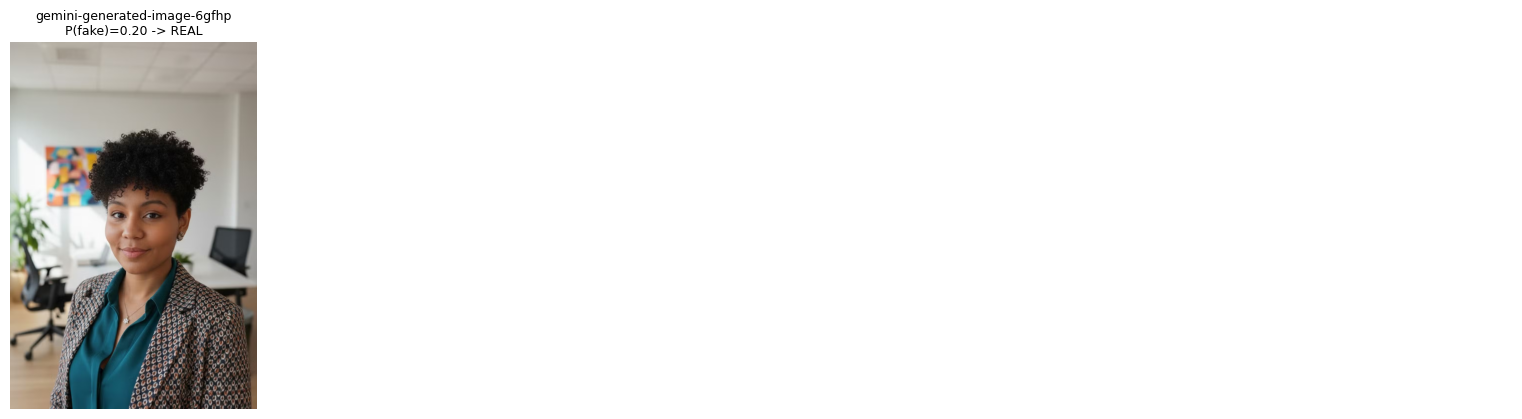

In [15]:
# Carrega o modelo final da Fase 3 se ele ainda não está na memória (sessão nova)
if "T" not in globals() or "thr" not in globals():
    ck3 = torch.load(os.path.join(RUN_DIR, "phase3_final.pt"), map_location="cpu", weights_only=False)
    cfg3 = ck3["cfg"]
    model = Phase2Detector(branches=cfg3["BRANCHES"], fusion=cfg3["FUSION"], proj_dim=cfg3["PROJ_DIM"], pretrained_cnn=False)
    model.load_state_dict(ck3["model_state_dict"])
    model = model.to(device)
    T, thr = float(ck3["temperature"]), float(ck3["threshold"])
model.eval()
print(f"Modelo pronto | T={T:.3f} | limiar={thr:.3f}")


def prep_like_training(im):
    # Replica o que os dados de treino sofreram: RGB, lado curto <= 512 e uma passada por JPEG q92
    im = im.convert("RGB")
    s = min(im.size)
    if s > CFG["SHORT_SIDE"]:
        k = CFG["SHORT_SIDE"] / s
        im = im.resize((round(im.width * k), round(im.height * k)), Image.LANCZOS)
    if min(im.size) < CROP:                       # menor que um recorte: amplia (resultado menos confiável)
        k = CROP / min(im.size)
        im = im.resize((math.ceil(im.width * k), math.ceil(im.height * k)), Image.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=CFG["JPEG_QUALITY"])
    buf.seek(0)
    return Image.open(buf).convert("RGB")


@torch.no_grad()
def predict_pils(pils, chunk=8):
    # devolve P(fake) calibrada e os pesos do gate (média dos 5 recortes) para uma lista de imagens PIL
    probs, gates = [], []
    for i in range(0, len(pils), chunk):
        x = torch.stack([multicrop_tf(prep_like_training(im)) for im in pils[i:i + chunk]]).to(device)   # (B,5,3,H,W)
        B = x.size(0)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            lg, g = model(x.flatten(0, 1), return_gate=True)
        probs.append(F.softmax(lg.float().view(B, 5, -1).mean(1) / T, 1)[:, 1].cpu())
        if g is not None:
            gates.append(g.float().view(B, 5, -1).mean(1).cpu())
    return torch.cat(probs).numpy(), (torch.cat(gates).numpy() if gates else None)


# ---------- A) Teste rápido: upload ou pasta do Drive ----------
import matplotlib.pyplot as plt
PASTA_DRIVE = None        # ex.: "/content/drive/MyDrive/TCC_Final/minhas_imagens"; None = abre o seletor de upload
EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
if PASTA_DRIVE:
    nomes = sorted(f for f in os.listdir(PASTA_DRIVE) if f.lower().endswith(EXTS))
    imagens = [(n, Image.open(os.path.join(PASTA_DRIVE, n))) for n in nomes]
else:
    from google.colab import files as colab_files
    up = colab_files.upload()
    imagens = [(n, Image.open(io.BytesIO(b))) for n, b in up.items() if n.lower().endswith(EXTS)]

if imagens:
    pf, gw = predict_pils([im for _, im in imagens])
    print(f"{'arquivo':40s}{'P(fake)':>9s}  decisão" + ("".join(f"{'gate_' + n:>10s}" for n in model.names) if gw is not None else ""))
    for i, (nome, im) in enumerate(imagens):
        aviso = "  (lado curto < 256: fora do que o modelo viu)" if min(im.size) < CFG["MIN_SIDE"] else ""
        print(f"{nome[:39]:40s}{pf[i]:9.3f}  {'FAKE' if pf[i] >= thr else 'REAL':5s}"
              + ("".join(f"{v:10.2f}" for v in gw[i]) if gw is not None else "") + aviso)
    cols = 4
    rows_n = max(1, math.ceil(len(imagens) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 4.3 * rows_n), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (nome, im), pp in zip(axes.ravel(), imagens, pf):
        ax.imshow(im.convert("RGB"))
        ax.set_title(f"{nome[:28]}\nP(fake)={pp:.2f} -> {'FAKE' if pp >= thr else 'REAL'}", fontsize=9)
    plt.tight_layout(); plt.show()

# ---------- B) Avaliação externa rotulada (opcional): pasta com real/ e fake/ ----------
EXT_DIR = None            # ex.: "/content/drive/MyDrive/TCC_Final/teste_externo"; None = pula esta parte
if EXT_DIR:
    ys, ps = [], []
    for lab, cls in ((0, "real"), (1, "fake")):
        d = os.path.join(EXT_DIR, cls)
        fs = [os.path.join(d, f) for f in sorted(os.listdir(d)) if f.lower().endswith(EXTS)]
        for i in range(0, len(fs), 64):                         # em blocos, para não encher a memória
            pils = [Image.open(p) for p in fs[i:i + 64]]
            p_, _ = predict_pils(pils)
            ps += p_.tolist(); ys += [lab] * len(pils)
    ys, ps = np.array(ys), np.array(ps)
    m = binary_metrics(ys, (ps >= thr).astype(int))
    print(f"Externo: {len(ys)} imagens (reais={(ys == 0).sum()}, fakes={(ys == 1).sum()}) | "
          f"acurácia balanceada={m['bal_acc']:.3f} | TNR={m['tnr']:.3f} | revocação={m['recall']:.3f}")
    if len(set(ys)) == 2:
        lo_e, hi_e = bootstrap_auc_ci(ys, ps)
        print(f"AUC={roc_auc_score(ys, ps):.4f} (IC95 {lo_e:.3f}-{hi_e:.3f})  <- com poucas imagens o intervalo será enorme")